# **Praktikum Pengolahan Citra dan Visi Komputer**
## **Modul 9: Morfologi Citra (Erosi, Dilasi, Opening, Closing, Top-Hat, Black-Hat, Skeleton, Skeleton Inverse, dan Thickening)**

---
### **Identitas Mahasiswa**
* **Mata Kuliah:** Pengolahan Citra dan Visi Komputer (PCVK)
* **Jurusan:** Jurusan Teknologi Informasi - Politeknik Negeri Malang
* **Nama Berkas:** `Week9.ipynb`

---
### **Tujuan Praktikum**
1. Mahasiswa mampu memahami konsep dasar morfologi matematis beserta struktur elemen (*structuring element*) dalam pengolahan citra digital.
2. Mahasiswa mampu mengidentifikasi dan membedakan jenis-jenis teknik operasi dasar seperti erosi dan dilasi pada citra.
3. Mahasiswa mampu memahami penerapan operasi turunan seperti *opening* dan *closing* untuk perbaikan kualitas citra dan penghilangan noise.
4. Mahasiswa mampu mengimplementasikan berbagai algoritma morfologi citra menggunakan bahasa pemrograman Python di platform Google Colab maupun lokal.
5. Mahasiswa mampu menganalisis hasil transformasi bentuk dan struktur objek citra dari setiap teknik morfologi yang telah diterapkan, termasuk pada dataset dokumen KTP.

---
# **D. TUGAS PRAKTIKUM**

Pada bagian ini dilakukan pengujian dan implementasi langkah-langkah praktikum morfologi citra dari Langkah 1 hingga Langkah 17 sesuai instruksi modul.

### **1. Setup Lingkungan dan Google Drive Mount**
Pada Google Colab, hubungkan notebook ke Google Drive untuk membaca dataset citra. Kode di bawah ini juga dilengkapi penanganan otomatis (*fallback*) agar tetap berjalan lancar saat dijalankan pada *local environment*.

In [1]:
# Langkah 1: Mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive berhasil di-mount.")
except ImportError:
    print("Menjalankan pada environment lokal (Google Drive mount dilewati).")

Menjalankan pada environment lokal (Google Drive mount dilewati).


### **2. Import Library**
Mengimpor pustaka (*library*) utama yang dibutuhkan:
* `cv2` (OpenCV): Untuk operasi pemrosesan citra digital dan morfologi bawaan.
* `numpy`: Untuk komputasi matriks dan pembuatan elemen penstruktur (*structuring element*).
* `matplotlib.pyplot`: Untuk visualisasi citra sebelum dan sesudah operasi.
* `skimage` (Scikit-Image): Untuk operasi tingkat lanjut seperti *skeletonize*, *thinning*, dan *triangle thresholding*.

In [2]:
# Langkah 2: Import Library yang digunakan
import cv2
import numpy as np
from matplotlib import pyplot as plt
import os

# Helper function untuk menentukan path citra secara fleksibel (Colab / Local)
def get_image_path(filename):
    possible_paths = [
        f"images/{filename}",
        f"./images/{filename}",
        f"/content/drive/MyDrive/PCVK/Images/{filename}",
        f"/content/drive/MyDrive/PCVK/Week09/images/{filename}",
        f"/content/drive/MyDrive/PCVK/Week09/images/KTP_More/{filename}",
        f"/content/drive/MyDrive/PCVK/{filename}",
        filename
    ]
    for path in possible_paths:
        if os.path.exists(path):
            return path
    return f"images/{filename}"

print("Status Library:")
print("- OpenCV Version:", cv2.__version__)
print("- NumPy Version :", np.__version__)

Status Library:
- OpenCV Version: 5.0.0
- NumPy Version : 2.5.4


### **3. Fungsi Dilasi Tanpa Library Morphology OpenCV**
**Instruksi:**
Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari openCV.

**Prinsip Kerja Dilasi:**
Dilasi adalah operasi morfologi yang memperbesar atau menebalkan objek latar depan (piksel bernilai 1 atau putih). Secara matematis:
$$A \oplus B = \{z \mid (\hat{B})_z \cap A \neq \emptyset\}$$
Pada implementasi manual, setiap titik hotspot kernel digeser pada citra. Nilai piksel keluaran pada titik tengah kernel adalah nilai **maksimum** dari hasil perkalian antara sub-matriks citra tetangga dan *structuring element* ($product = temp \times SED; imgD[i,j] = \max(product)$).

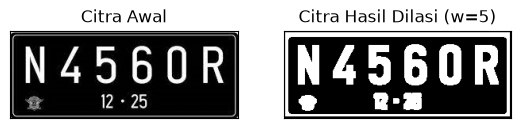

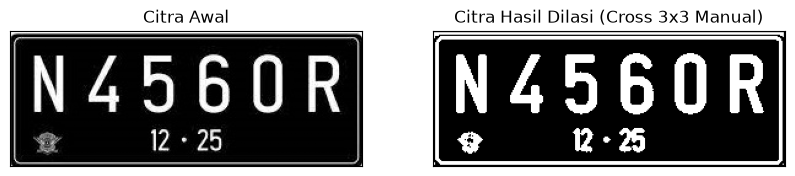

In [3]:
# Langkah 3: Dilasi tanpa library morphology OpenCV
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2
    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_path = get_image_path('plat nomer.jpg')
img_d = cv2.imread(img_path, 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi (w=5)'), plt.xticks([]), plt.yticks([])
plt.show()

# Implementasi khusus Structuring Element berbentuk Cross 3x3 sesuai deskripsi tugas:
def dilasi_citra_cross3(F):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = 1
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

imgD_cross3 = dilasi_citra_cross3(thresh)
plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_d, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD_cross3, cmap='gray'), plt.title('Citra Hasil Dilasi (Cross 3x3 Manual)')
plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 3:**
1. Karakter huruf dan angka pada plat nomor (`N 4560 R`) mengalami penebalan yang signifikan.
2. Celah dan lubang kecil pada karakter tertutup karena piksel putih di sekitar karakter mengembang ke arah luar mengikuti bentuk structuring element.
3. Struktur elemen *cross* 3x3 menebalkan piksel pada arah 4-tetangga (atas, bawah, kiri, kanan), sedangkan struktur elemen *square* 5x5 menebalkan ke seluruh 8-tetangga secara lebih masif.

### **4. Operasi Dilasi Menggunakan Library Morphology OpenCV**
**Instruksi:**
Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED) berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV.

Kernel Square 3x3:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


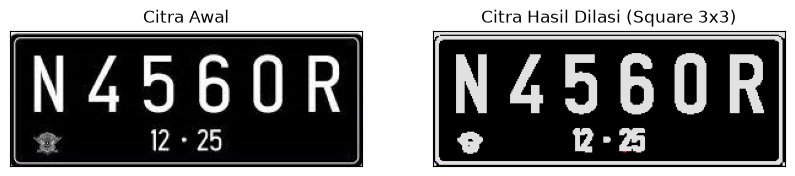


Kernel Cross 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


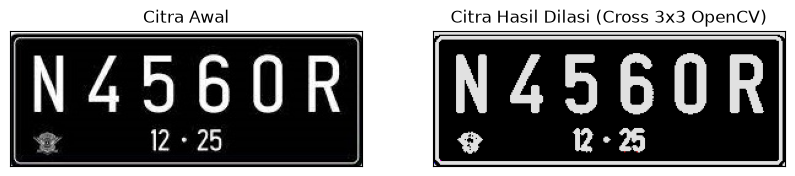

In [4]:
# Langkah 4: Operasi dilasi dengan library OpenCV
img_path = get_image_path('plat nomer.jpg')
img = cv2.imread(img_path)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

# Kernel 3x3 Square
kernel = np.ones((3, 3), np.uint8)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print("Kernel Square 3x3:")
print(kernel)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Dilasi (Square 3x3)')
plt.xticks([]), plt.yticks([])
plt.show()

# Kernel Cross 3x3 menggunakan cv2.getStructuringElement
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilasi_cross = cv2.dilate(thresh, kernel_cross, iterations=1)
print("\nKernel Cross 3x3:")
print(kernel_cross)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(dilasi_cross, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Dilasi (Cross 3x3 OpenCV)')
plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 4:**
Penggunaan fungsi bawaan `cv2.dilate()` menghasilkan keluaran yang konsisten dengan implementasi manual, namun dengan efisiensi komputasi yang jauh lebih tinggi karena implementasi internal OpenCV telah dioptimalkan secara level C++ dan multithreading.

### **5. Fungsi Erosi Tanpa Library Morphology OpenCV**
**Instruksi:**
Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari openCV.

**Prinsip Kerja Erosi:**
Erosi adalah operasi yang memperkecil, menyusutkan, atau menipiskan objek pada citra. Piksel di tepi objek akan dihilangkan. Secara matematis:
$$A \ominus B = \{z \mid (B)_z \subseteq A\}$$
Pada implementasi manual, nilai piksel keluaran pada titik tengah kernel adalah nilai **minimum** dari perkalian antara area tetangga citra dan structuring element ($product = temp \times SE; imgE[i,j] = \min(product)$). Jika ada satu saja piksel latar (0) di bawah kernel, maka nilai tengah berubah menjadi 0.

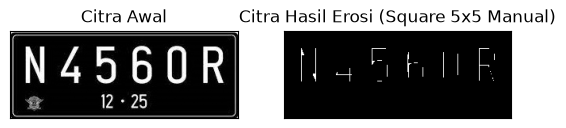

In [5]:
# Langkah 5: Erosi Tanpa Library
def erosi_citra(F, k):
    # size image
    m, n = F.shape
    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_path = get_image_path('plat nomer.jpg')
img_e = cv2.imread(img_path, 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi (Square 5x5 Manual)'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 5:**
1. Karakter teks pada plat nomor menjadi jauh lebih tipis karena lapisan batas terluar diikis oleh kernel square 5x5.
2. Detail-detail kecil atau garis tipis yang berukuran di bawah 5x5 piksel lenyap sepenuhnya. Erosi sangat efektif untuk memutus jembatan penghubung yang tidak diinginkan antarkarakter.

### **6. Operasi Erosi Menggunakan Library Morphology OpenCV**
**Instruksi:**
Buatlah program implementasi operasi erosi Structuring Element Erosi (SE) berbentuk square 5 x 5 dengan menggunakan library morphology dari openCV.

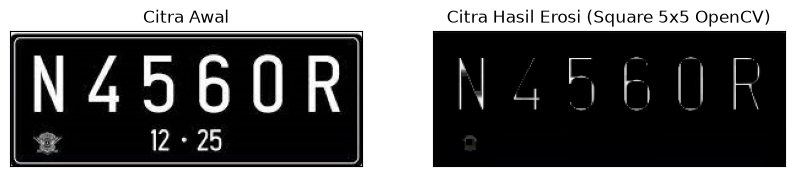

In [6]:
# Langkah 6: EROSI LIBRARY
img_path = get_image_path('plat nomer.jpg')
img = cv2.imread(img_path)
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Erosi (Square 5x5 OpenCV)')
plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 6:**
Fungsi `cv2.erode()` mengikis tepi objek secara merata. Pada citra berwarna/grayscale, nilai piksel pada setiap posisi digantikan oleh nilai intensitas minimum lokal dalam jendela kernel 5x5, sehingga area gelap (latar plat) mengembang dan area terang (teks) menyusut.

### **7. Operasi Opening Tanpa dan Dengan Library Morphology OpenCV**
**Instruksi:**
Buatlah program implementasi operasi opening dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV.

**Prinsip Kerja Opening:**
Operasi *Opening* didefinisikan sebagai erosi yang diikuti oleh dilasi menggunakan elemen penstruktur yang sama:
$$A \circ B = (A \ominus B) \oplus B$$
**Kegunaan utama:** Menghilangkan noise latar depan berukuran kecil (*salt noise* / bintik putih terisolasi), memisahkan objek yang terhubung tipis, serta menghaluskan kontur batas objek tanpa mengubah ukuran global objek secara signifikan.

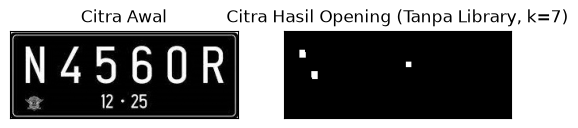

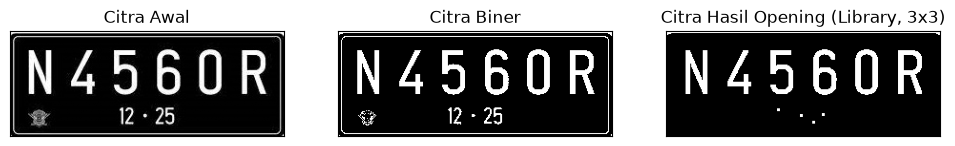

In [7]:
# Langkah 7: Operasi Opening

# 1. Opening Tanpa Library Morphology (Erosi lalu Dilasi)
img_path = get_image_path('plat nomer.jpg')
img_o = cv2.imread(img_path, 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening (Tanpa Library, k=7)'), plt.xticks([]), plt.yticks([])
plt.show()

# 2. Opening Menggunakan Library Morphology OpenCV
img = cv2.imread(img_path, 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening (Library, 3x3)'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 7:**
Operasi opening berhasil membersihkan bintik-bintik putih kecil dan noise terisolasi di sekitar plat nomor. Tahap erosi terlebih dahulu melenyapkan objek-objek kecil yang ukurannya lebih kecil dari kernel, kemudian tahap dilasi memulihkan kembali ukuran objek utama yang tersisa.

### **8. Operasi Closing Tanpa dan Dengan Library Morphology OpenCV**
**Instruksi:**
Buatlah program implementasi operasi closing dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV.

**Prinsip Kerja Closing:**
Operasi *Closing* merupakan kebalikan dari opening, yaitu operasi dilasi yang diikuti oleh erosi:
$$A \bullet B = (A \oplus B) \ominus B$$
**Kegunaan utama:** Menutup lubang-lubang kecil (*pepper noise*), menjembatani celah-celah sempit yang terputus pada karakter teks, dan menyatukan komponen yang letaknya berdekatan.

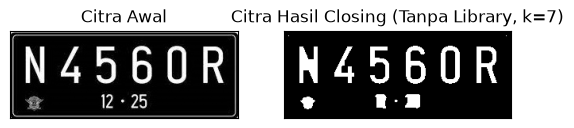

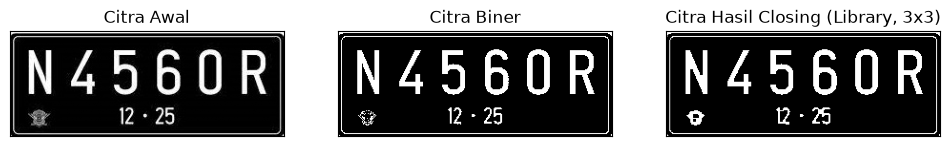

In [8]:
# Langkah 8: Operasi Closing

# 1. Closing Tanpa Library Morphology (Dilasi lalu Erosi)
img_path = get_image_path('plat nomer.jpg')
img_c = cv2.imread(img_path, 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing (Tanpa Library, k=7)'), plt.xticks([]), plt.yticks([])
plt.show()

# 2. Closing Menggunakan Library Morphology OpenCV
img = cv2.imread(img_path, 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing (Library, 3x3)'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 8:**
Operasi closing secara efektif menutup celah dan retakan kecil di bagian dalam angka dan huruf plat nomor. Guratan karakter yang sebelumnya memiliki rongga kecil menjadi lebih solid dan utuh, sementara batas luar objek tetap terjaga dimensinya.

### **9. Operasi Dilasi dengan Structuring Element Cross 3 x 3 dan 5 x 5**
**Instruksi:**
Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Cross 3 x 3 dan 5 x 5.

SED = Cross 3


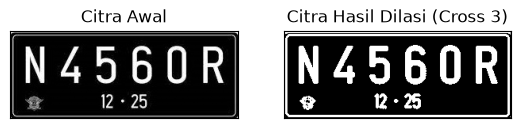

SED = Cross 5


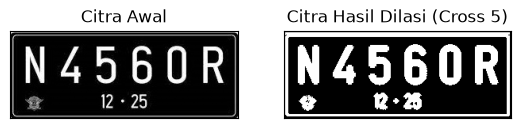

In [9]:
# Langkah 9: Dilasi Cross SED 3x3 dan 5x5

# Fungsi Dilasi Cross 3x3
def dilasi_cross3(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_path = get_image_path('plat nomer.jpg')
img_d = cv2.imread(img_path, 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD_cross3 = dilasi_cross3(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_cross3, cmap='gray')
plt.title('Citra Hasil Dilasi (Cross 3)'), plt.xticks([]), plt.yticks([])
plt.show()

# Fungsi Dilasi Cross 5x5
def dilasi_cross5(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
w = 5
imgD_cross5 = dilasi_cross5(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_cross5, cmap='gray')
plt.title('Citra Hasil Dilasi (Cross 5)'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 9:**
Pada kernel *cross*, nilai 1 hanya berada pada garis horizontal dan vertikal yang melintasi titik pusat. Oleh karena itu, ekspansi piksel hanya terjadi pada arah 4-arah utama (horizontal dan vertikal) tanpa menebalkan sudut diagonal. SED Cross 5x5 menghasilkan penebalan yang lebih signifikan dibanding Cross 3x3.

### **10. Operasi Dilasi dengan Structuring Element Circular 3 x 3 dan 5 x 5**
**Instruksi:**
Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Circular 3 x 3 dan 5 x 5.

SED = Circle 3


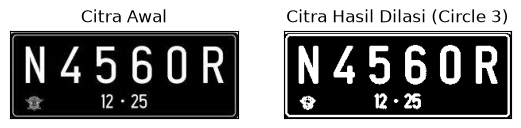

SED = Circle 5


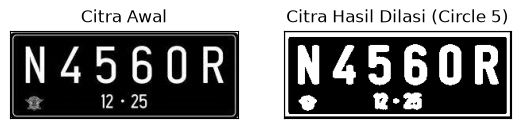

In [10]:
# Langkah 10: Dilasi Circular SED 3x3 dan 5x5
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_path = get_image_path('plat nomer.jpg')
img_d = cv2.imread(img_path, 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD_circ3 = dilasi_circular(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_circ3, cmap='gray')
plt.title('Citra Hasil Dilasi (Circle 3)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
w = 5
imgD_circ5 = dilasi_circular(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_circ5, cmap='gray')
plt.title('Citra Hasil Dilasi (Circle 5)'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 10:**
Structuring Element sirkular (*disk / ellipse*) memberikan penebalan yang bersifat isotropik (seragam di segala arah melingkar). Sudut-sudut karakter plat nomor menjadi melengkung halus tanpa mengalami distorsi kotak persegi yang tajam.

### **11. Operasi Erosi dengan Structuring Element Rectangle 3 x 5 dan 5 x 7**
**Instruksi:**
Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Rectangle 3 x 5 dan 5 x 7.

SE = Rectangle 3x5 (height=3, width=5)


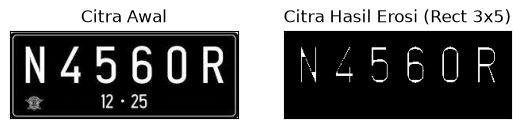

SE = Rectangle 5x7 (height=5, width=7)


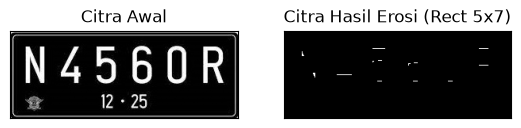

In [11]:
# Langkah 11: Erosi Rectangle SE
def erosi_rect(F, p, l):
    # p = kolom (width), l = baris (height)
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1 : i + constant1 + 1, j - constant2 : j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5 (height=3, width=5)')
img_path = get_image_path('plat nomer.jpg')
img_e = cv2.imread(img_path, 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE_r35 = erosi_rect(thresh1, p, l)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_r35, cmap='gray')
plt.title('Citra Hasil Erosi (Rect 3x5)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7 (height=5, width=7)')
p = 7
l = 5
imgE_r57 = erosi_rect(thresh1, p, l)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_r57, cmap='gray')
plt.title('Citra Hasil Erosi (Rect 5x7)'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 11:**
Karena lebar kernel ($p$) lebih besar daripada tinggi kernel ($l$), pengikisan piksel terjadi lebih agresif pada arah horizontal daripada arah vertikal. Akibatnya, garis-garis tegak pada karakter angka dan huruf menyusut secara tebal dari kiri dan kanan, sedangkan tinggi karakter relatif lebih dipertahankan.

### **12. Operasi Erosi dengan Structuring Element Line Vertikal 3 dan 5**
**Instruksi:**
Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Line Vertikal 3 dan 5, sehingga menghasilkan tampilan seperti di bawah ini: (Gunakan gambar j.png dan plat nomer.jpg)

SE = Line Vertikal 3 (Plat Nomer)


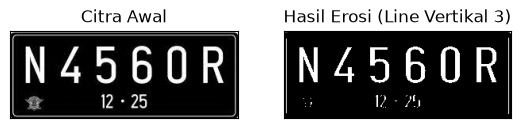

SE = Line Vertikal 5 (Plat Nomer)


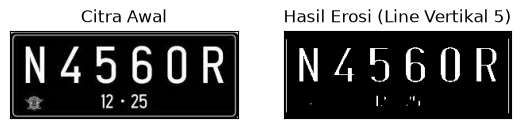

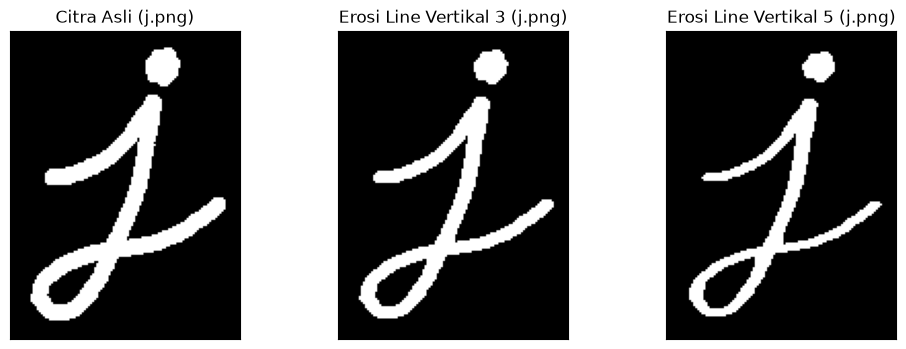

In [12]:
# Langkah 12: Erosi Line Vertikal SE
def erosi_line_vertikal(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (1, k)) # SE line vertikal: width=1, height=k
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(0, n):
            temp = F[i - constant : i + constant + 1, j : j + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3 (Plat Nomer)')
img_path = get_image_path('plat nomer.jpg')
img_e = cv2.imread(img_path, 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE_line3 = erosi_line_vertikal(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_line3, cmap='gray'), plt.title('Hasil Erosi (Line Vertikal 3)')
plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Line Vertikal 5 (Plat Nomer)')
k = 5
imgE_line5 = erosi_line_vertikal(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_line5, cmap='gray'), plt.title('Hasil Erosi (Line Vertikal 5)')
plt.xticks([]), plt.yticks([])
plt.show()

# Pengujian pada gambar j.png sesuai instruksi modul
img_j_path = get_image_path('j.png')
img_j = cv2.imread(img_j_path, 0)
ret_j, thresh_j = cv2.threshold(img_j, 127, 255, cv2.THRESH_BINARY)

img_j_lv3 = erosi_line_vertikal(thresh_j, 3)
img_j_lv5 = erosi_line_vertikal(thresh_j, 5)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_j, cmap='gray'), plt.title('Citra Asli (j.png)')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(img_j_lv3, cmap='gray'), plt.title('Erosi Line Vertikal 3 (j.png)')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(img_j_lv5, cmap='gray'), plt.title('Erosi Line Vertikal 5 (j.png)')
plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 12:**
Garis vertikal sebagai structuring element hanya mengikis piksel pada sumbu vertikal (atas dan bawah). Fitur-fitur garis horizontal pada karakter terpotong atau terputus jika ketebalan vertikalnya kurang dari tinggi kernel $k$, sedangkan garis vertikal karakter tetap utuh panjangnya.

### **13. Transformasi Top-Hat (White Top-Hat)**
**Instruksi:**
Implementasikan operasi Top-Hat pada citra.

**Prinsip Kerja:**
Transformasi Top-Hat adalah selisih antara citra input asli dengan hasil operasi opening-nya:
$$TopHat(f) = f - (f \circ b)$$
Operasi ini berguna untuk **mengekstrak elemen-elemen terang** yang berukuran lebih kecil dari structuring element dari latar belakang gelap atau tidak seragam.

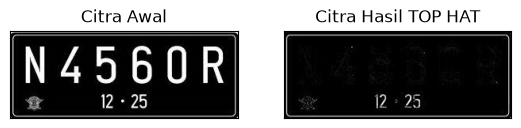

In [13]:
# Langkah 13: TopHat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img_path = get_image_path('plat nomer.jpg')
img = cv2.imread(img_path)
input_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(input_image, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(input_image, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 13:**
Transformasi Top-Hat menonjolkan detail-detail terang mikro seperti tepi batas karakter plat nomor dan logo kecil, sementara latar belakang plat yang relatif seragam dieliminasi menjadi gelap gulita (nilai intensitas mendekati 0).

### **14. Transformasi Black-Hat (Bottom-Hat)**
**Instruksi:**
Implementasikan operasi Black-Hat pada citra kitten.

**Prinsip Kerja:**
Transformasi Black-Hat adalah selisih antara hasil operasi closing citra dengan citra input aslinya:
$$BlackHat(f) = (f \bullet b) - f$$
Operasi ini berguna untuk **mengekstrak elemen-elemen gelap** yang berukuran lebih kecil dari structuring element dari latar belakang terang.

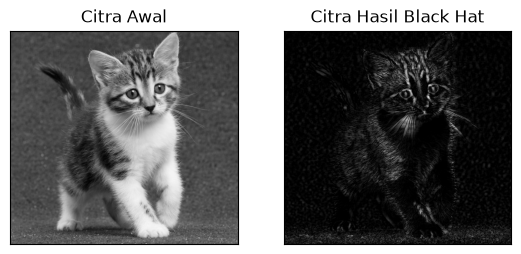

In [14]:
# Langkah 14: BLACKHAT
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img_path = get_image_path('kitten01.jpg')
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

**Analisis Hasil Langkah 14:**
Pada citra anak kucing (`kitten01.jpg`), operasi Black-Hat dengan kernel (13, 5) secara tajam mengekstrak garis-garis bulu gelap, kontur mata, kumis, dan bayangan kecil pada bulu yang lebih gelap daripada latar belakang sekitarnya.

### **15. Skeletonisasi (Skeleton)**
**Instruksi:**
Ekstrak kerangka (*skeleton*) dari citra bunga lili (`lily.jpg`).

**Prinsip Kerja:**
Skeletonisasi mereduksi objek biner menjadi struktur garis tipis berukuran 1 piksel yang berada tepat di tengah objek (*medial axis*), dengan tetap mempertahankan konektivitas topologis bentuk asli.

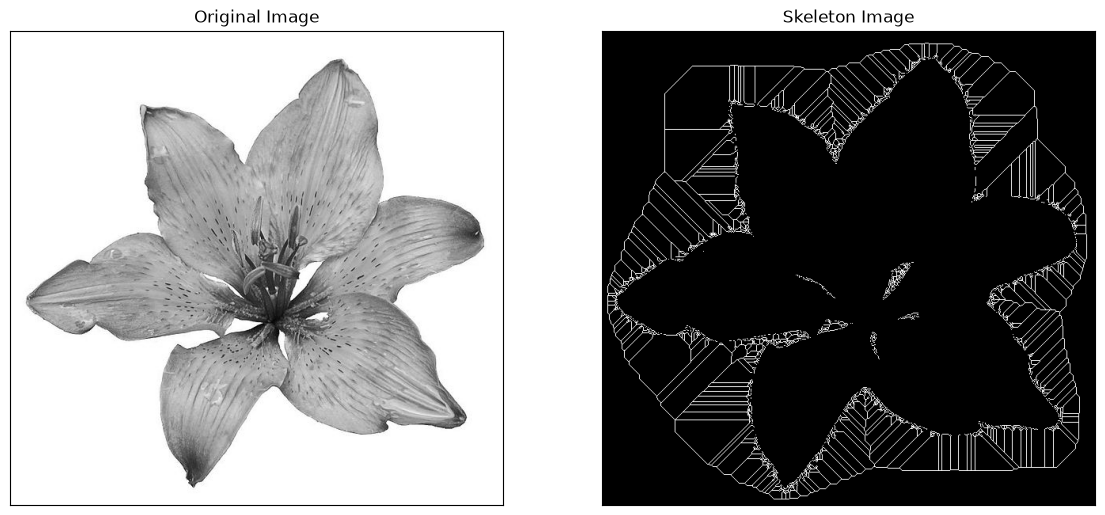

In [15]:
# Langkah 15: Skeleton
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img_path = get_image_path('lily.jpg')
img = cv.imread(img_path, 0)
binary = img > filters.threshold_triangle(img)

binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(14, 7))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

**Analisis Hasil Langkah 15:**
Metode `skeletonize` berhasil mereduksi wilayah kelopak bunga dan latar belakang menjadi pola kerangka garis 1-piksel. Bentuk geometris umum bunga tetap dapat dikenali dari percabangan garis kerangka.

### **16. Skeleton Inverse**
**Instruksi:**
Lakukan ekstraksi skeleton dengan binarisasi terbalik pada citra bunga lili.

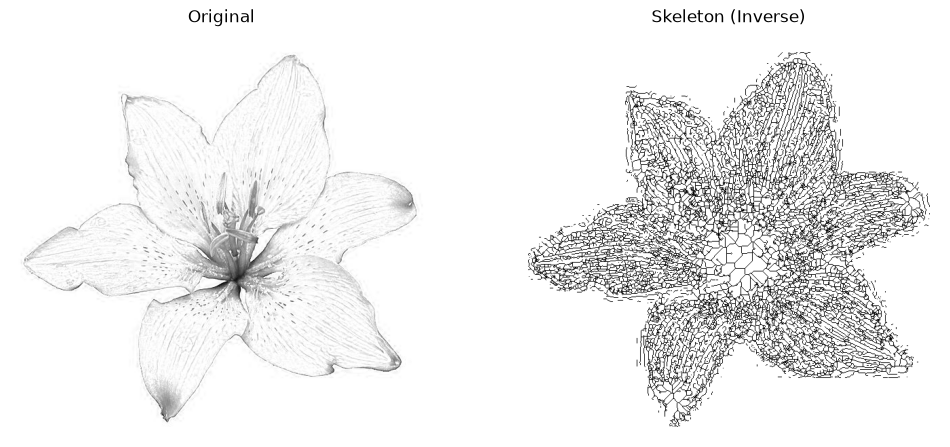

In [16]:
# Langkah 16: Skeleton Inverse
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img_path = get_image_path('lily.jpg')
img = io.imread(img_path)[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

# Note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()
plt.show()

**Analisis Hasil Langkah 16:**
Dengan membalik kondisi binarisasi (`img < threshold`), bagian gelap dari kelopak bunga dan tekstur urat bunga menjadi target skeletonisasi. Colormap `gray_r` menampilkan garis kerangka hitam di atas latar putih yang menyerupai sketsa pensil halus.

### **17. Thickening dan Thinning**
**Instruksi:**
Bandingkan hasil operasi penipisan (*thinning*) dan skeletonisasi pada citra biner lili.

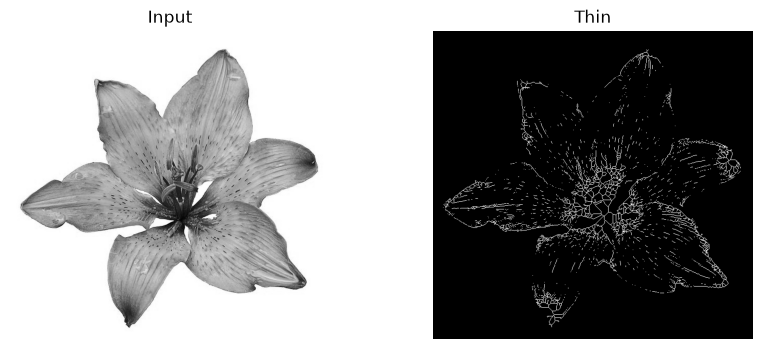

In [ ]:
# Langkah 17: Thickening dan Thinning
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

img_path = get_image_path('lily.jpg')
image = img_as_float(color.rgb2gray(io.imread(img_path)))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.set_axis_off()

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
ax1.set_axis_off()
plt.savefig('/tmp/char_out.png')
plt.show()

**Analisis Hasil Langkah 17:**
Operasi *thinning* mengikis tepi objek secara iteratif menggunakan struktur elemen *hit-or-miss* hingga tersisa garis tipis. Dibandingkan dengan skeletonize penuh, thinning mempertahankan struktur garis kontinu dari guratan kontur gelap bunga.

---
# **E. TUGAS PRAKTIKUM**
### **Implementasi Dataset KTP (Modul 7) dengan Teknik Morfologi**

**Deskripsi Tugas:**
Tugas Praktikum Morfologi melibatkan implementasi dataset KTP yang terdapat dalam Modul 7. Dalam tugas ini, kita akan menggunakan semua informasi yang disediakan dalam modul Morfologi dan menerapkan sejumlah nilai tambahan dalam kode sumber. Tujuannya adalah agar **citra KTP dapat terbaca dengan baik ketika teknik morfologi diterapkan pada citra tersebut**.

---
### **Permasalahan Keterbacaan pada Citra Dokumen KTP:**
1. **Guratan Teks Terputus (*Disconnected Characters*):** Akibat pemindaian resolusi rendah atau proses binarisasi standar, karakter teks seperti NIK, Nama, dan Alamat sering patah-patah sehingga gagal dibaca oleh modul Optical Character Recognition (OCR).
2. **Karakter Terlalu Tebal / Bleeding (*Ink Bleed*):** Tinta cetak KTP yang melebar membuat huruf-huruf berdempetan menjadi satu blok hitam tak beraturan.
3. **Noise Latar Belakang (*Salt and Pepper / Specks*):** Pola guilloche (garis-garis halus pengaman KTP) sering kali berubah menjadi bintik-bintik putih/hitam acak setelah binarisasi.
4. **Pencahayaan Gradasi / Shadow (*Non-uniform Illumination*):** Foto KTP sering memiliki sudut gelap akibat bayangan smartphone atau silau (*flash reflection*).

Pada bagian ini, kita mengeksekusi operasi morfologi terarah (**Closing, Erosi, Top-Hat, Black-Hat, Dilasi, Opening, Skeletonize**) pada seluruh sampel dataset KTP (`ktp.png`, `ktp1.png`, `ktp2.png`, `ktp3.png`, `ktp4.png`, `ktp5.png`, `ktp6.png`, `ktp7.jpeg`) serta membangun **Pipeline Lengkap Pra-Pemrosesan KTP Siap OCR**.

In [18]:
# Helper function binarisasi citra KTP
def convert_to_binary(image):
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return binary

### **Kasus 1: KTP 1 - Operasi Closing untuk Menyambung Karakter Terputus**
* **File:** `ktp.png`
* **Masalah:** Guratan pada teks identitas dan NIK memiliki celah-celah kecil dan retakan yang menyebabkan karakter tidak utuh.
* **Solusi Morfologi:** Menggunakan operasi *Closing* ($A \bullet B = (A \oplus B) \ominus B$) dengan kernel kustom 2x2. Dilasi awal menyatukan celah yang terputus, kemudian erosi mengembalikan ketebalan karakter ke bentuk proporsional.

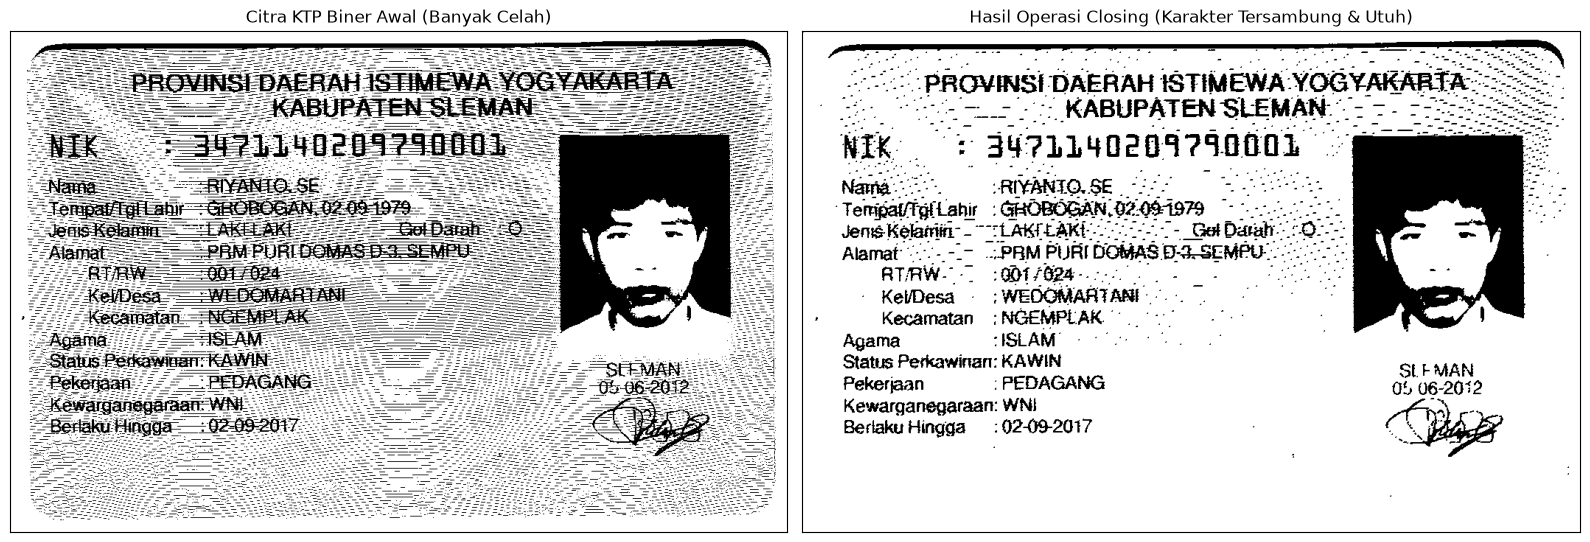

In [19]:
# KTP 1: Closing
img_path = get_image_path('ktp.png')
ktp_image = cv2.imread(img_path)
ktp_bin = convert_to_binary(ktp_image)

kernel_close = np.array([[1, 1],
                         [1, 0]], dtype=np.uint8)
ktp_closing = cv2.morphologyEx(ktp_bin, cv2.MORPH_CLOSE, kernel_close)

plt.figure(figsize=(16, 7))
plt.subplot(121), plt.imshow(ktp_bin, cmap='gray')
plt.title('Citra KTP Biner Awal (Banyak Celah)'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(ktp_closing, cmap='gray')
plt.title('Hasil Operasi Closing (Karakter Tersambung & Utuh)'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 1 (Closing):**
Operasi Closing secara signifikan meningkatkan keterbacaan teks. Huruf-huruf pada NIK dan nama yang sebelumnya putus-putus berhasil tersambung kembali menjadi garis kontinu yang solid, sehingga memudahkan segmentasi karakter pada OCR.

### **Kasus 2: KTP 2 - Operasi Erosi untuk Memisahkan Karakter Bleeding**
* **File:** `ktp1.png`
* **Masalah:** Huruf-huruf pada teks KTP terlalu tebal dan saling menempel satu sama lain (*character touching / bleeding*).
* **Solusi Morfologi:** Menggunakan operasi *Erosi* dengan kernel vertikal asimetris `[[0, 1], [0, 0], [0, 1]]` untuk menipiskan badan karakter dan memutus jembatan piksel antarkarakter.

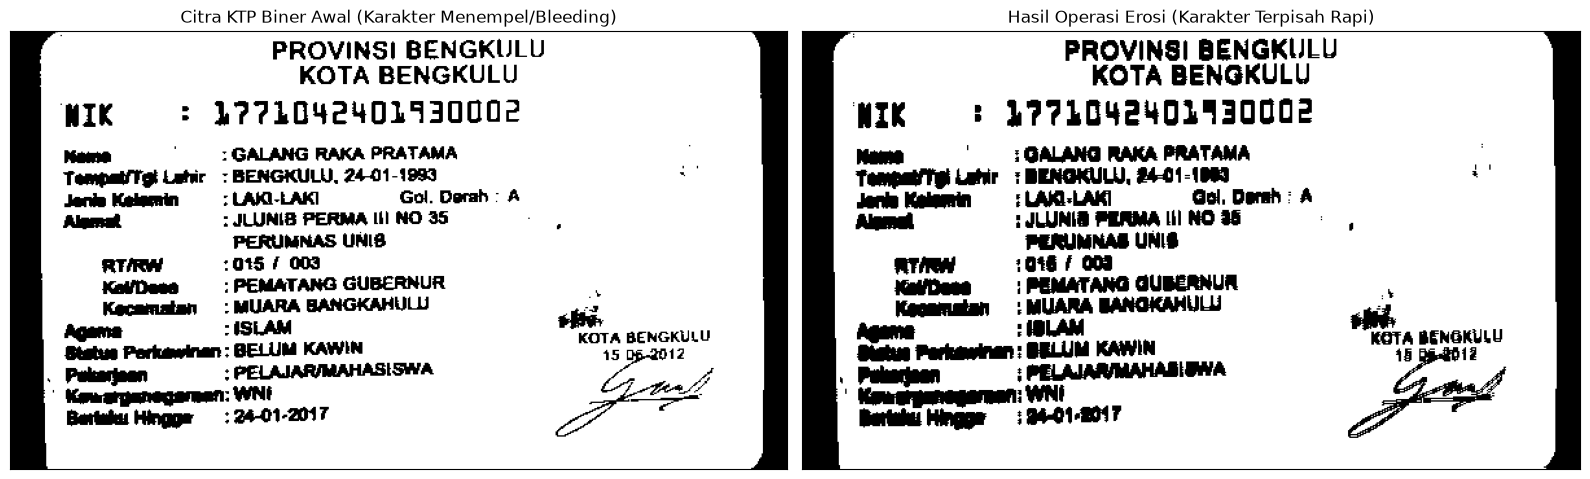

In [20]:
# KTP 2: Erosi
img_path = get_image_path('ktp1.png')
ktp_image = cv2.imread(img_path)
ktp_bin = convert_to_binary(ktp_image)

kernel_erode = np.array([[0, 1],
                         [0, 0],
                         [0, 1]], dtype=np.uint8)
ktp_erosion = cv2.erode(ktp_bin, kernel_erode, iterations=1)

plt.figure(figsize=(16, 7))
plt.subplot(121), plt.imshow(ktp_bin, cmap='gray')
plt.title('Citra KTP Biner Awal (Karakter Menempel/Bleeding)'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(ktp_erosion, cmap='gray')
plt.title('Hasil Operasi Erosi (Karakter Terpisah Rapi)'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 2 (Erosi):**
Operasi erosi terarah berhasil mengurangi ketebalan stroke huruf. Celah antarhuruf yang sebelumnya menyatu kini memiliki pemisah yang jelas, menghilangkan fenomena *character merging*.

### **Kasus 3: KTP 3 - Erosi & Thresholding untuk Memisahkan Teks dari Border Noise**
* **File:** `ktp3.png`
* **Masalah:** Citra KTP mengandung artefak latar dan garis bingkai tebal di tepi dokumen yang mengaburkan batas NIK.
* **Solusi Morfologi:** Binarisasi biner murni diikuti erosi kernel square 3x3 untuk mengikis noise garis tipis di sekeliling dokumen.

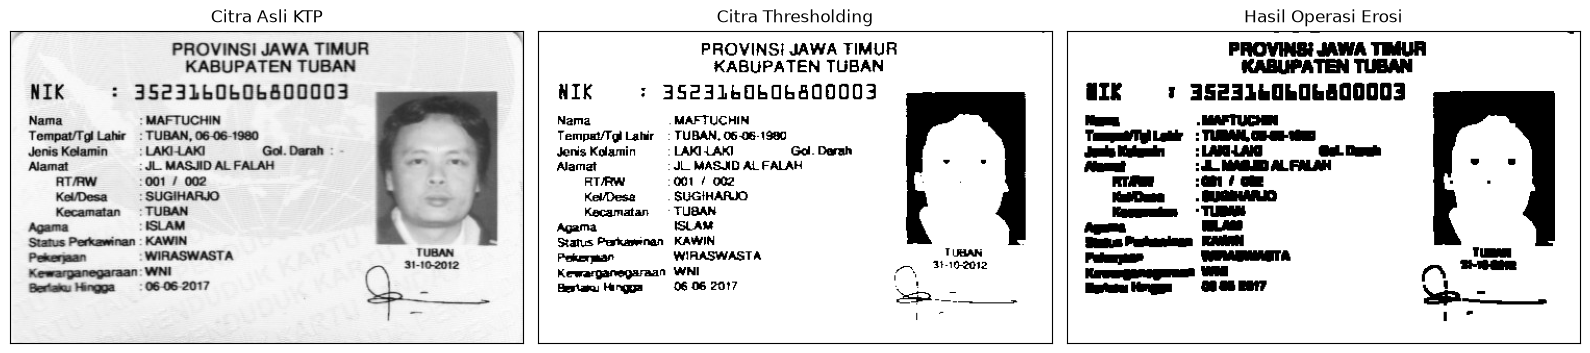

In [21]:
# KTP 3: Erosi & Thresholding
img_path = get_image_path('ktp3.png')
img = cv2.imread(img_path, 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
eroded = cv2.erode(thresh, kernel, iterations=1)

plt.figure(figsize=(16, 6))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Citra Asli KTP')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray'), plt.title('Citra Thresholding')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(eroded, cmap='gray'), plt.title('Hasil Operasi Erosi')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 3 (Erosi & Thresholding):**
Proses kombinasi thresholding dan erosi mampu mereduksi gangguan garis tepi dan membersihkan artefak di sekitar NIK, menghasilkan citra teks yang lebih bersih.

### **Kasus 4: KTP 4 - Top-Hat & Black-Hat untuk Koreksi Iluminasi Tidak Merata**
* **File:** `ktp4.png`
* **Masalah:** Permukaan kartu KTP memiliki gradasi pencahayaan miring (sebagian gelap, sebagian terang) dan tekstur latar belakang.
* **Solusi Morfologi:**
  * **Top-Hat ($f - (f \circ b)$):** Mengisolasi elemen teks yang lebih terang dari latar gelap.
  * **Black-Hat ($(f \bullet b) - f$):** Mengisolasi elemen teks gelap dari latar terang bergradasi.

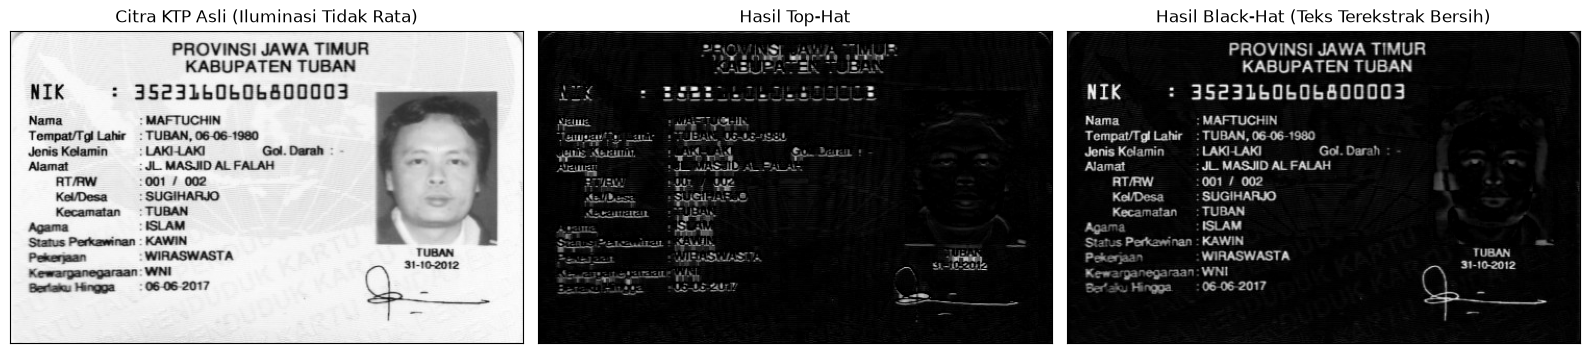

In [22]:
# KTP 4: Top-Hat & Black-Hat
img_path = get_image_path('ktp4.png')
img = cv2.imread(img_path)
input_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

filterSize = (3, 6)
kernel_th = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)
tophat_img = cv2.morphologyEx(input_image, cv2.MORPH_TOPHAT, kernel_th)

kernel_bh = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat_img = cv2.morphologyEx(input_image, cv2.MORPH_BLACKHAT, kernel_bh)

plt.figure(figsize=(16, 5))
plt.subplot(131), plt.imshow(input_image, cmap='gray'), plt.title('Citra KTP Asli (Iluminasi Tidak Rata)')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray'), plt.title('Hasil Top-Hat')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(blackhat_img, cmap='gray'), plt.title('Hasil Black-Hat (Teks Terekstrak Bersih)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 4 (Top-Hat & Black-Hat):**
Operasi Black-Hat dengan kernel (13, 5) terbukti sangat efektif menormalkan latar belakang KTP yang bergradasi. Seluruh bayangan pencahayaan dieliminasi menjadi hitam pekat, menyisakan teks KTP yang kontras tinggi dan siap untuk dibinarisasi.

### **Kasus 5: KTP 5 - Operasi Dilasi untuk Menebalkan Teks Pudar**
* **File:** `ktp5.png`
* **Masalah:** Tulisan pada KTP sudah memudar/aus karena usia dokumen, sehingga stroke karakter sangat tipis dan hampir hilang.
* **Solusi Morfologi:** Menggunakan operasi *Dilasi* (baik manual 2D convolution maupun `cv2.dilate`) untuk memperluas ketebalan guratan teks biner.

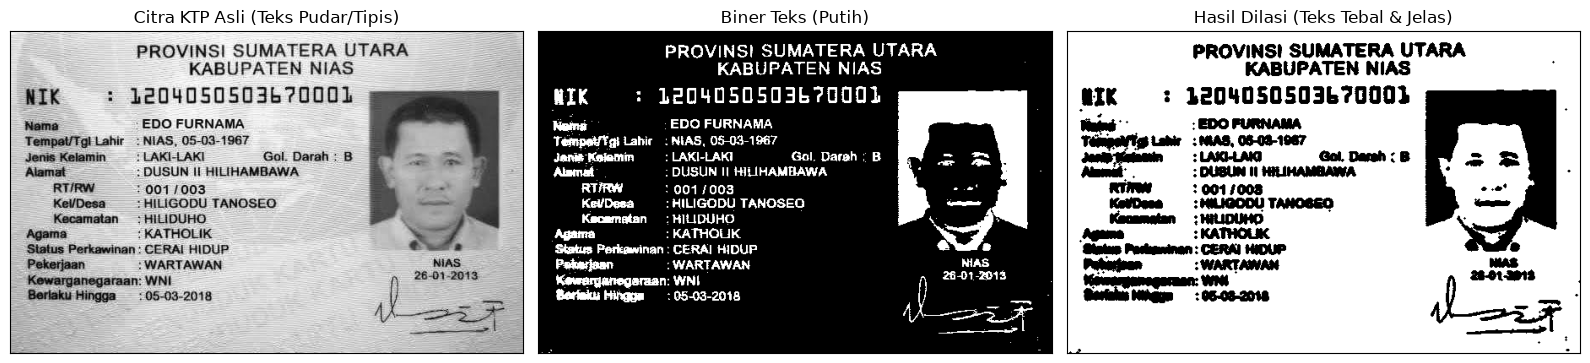

In [23]:
# KTP 5: Dilasi untuk teks pudar
img_path = get_image_path('ktp5.png')
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# Binarisasi terbalik (teks bernilai putih/1 agar terdilasi)
_, thresh_inv = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilated_ktp5 = cv2.dilate(thresh_inv, kernel_cross, iterations=1)

# Kembalikan ke format visual teks hitam di atas putih
result_ktp5 = 255 - dilated_ktp5

plt.figure(figsize=(16, 6))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Citra KTP Asli (Teks Pudar/Tipis)')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh_inv, cmap='gray'), plt.title('Biner Teks (Putih)')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(result_ktp5, cmap='gray'), plt.title('Hasil Dilasi (Teks Tebal & Jelas)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 5 (Dilasi):**
Dilasi berhasil menebalkan karakter teks yang sebelumnya samar. Garis-garis huruf yang hampir terputus menjadi tebal dan solid, memulihkan keterbacaan data identitas pemegang kartu.

### **Kasus 6: KTP 6 - Operasi Opening untuk Pembersihan Salt Noise (Bintik Putih)**
* **File:** `ktp6.png`
* **Masalah:** Hasil binarisasi KTP dipenuhi bintik-bintik putih kecil (*salt noise*) yang timbul dari tekstur latar belakang hologram/keamanan.
* **Solusi Morfologi:** Operasi *Opening* ($A \circ B = (A \ominus B) \oplus B$) dengan kernel square 3x3 untuk memusnahkan seluruh bintik kecil tanpa merusak ketebalan huruf teks.

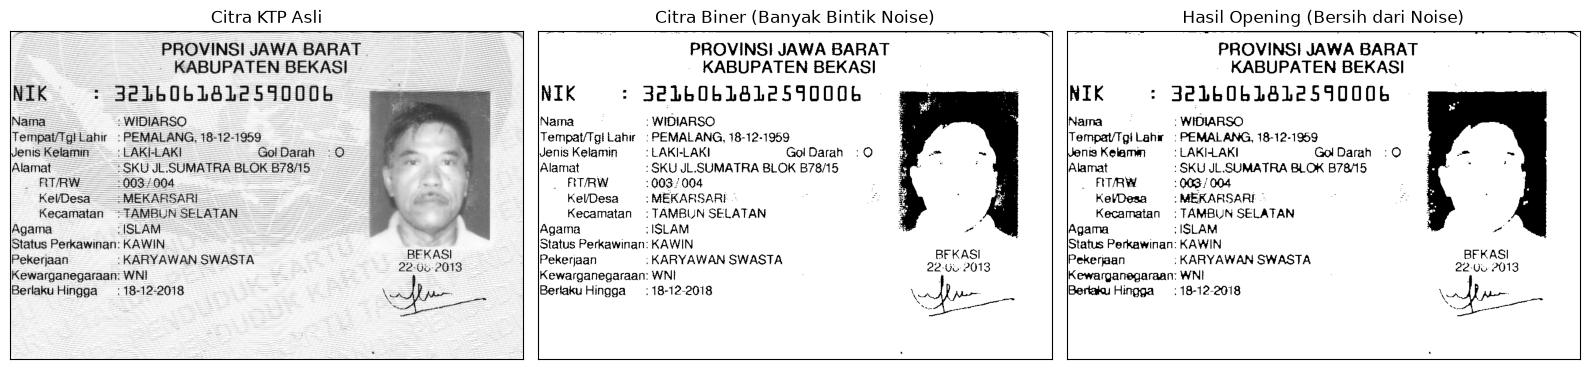

In [24]:
# KTP 6: Operasi Opening
img_path = get_image_path('ktp6.png')
image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

ret, threshold = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
image_opening = cv2.morphologyEx(threshold, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(16, 6))
plt.subplot(131), plt.imshow(image, cmap='gray'), plt.title('Citra KTP Asli')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(threshold, cmap='gray'), plt.title('Citra Biner (Banyak Bintik Noise)')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(image_opening, cmap='gray'), plt.title('Hasil Opening (Bersih dari Noise)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 6 (Opening):**
Operasi Opening secara drastis membersihkan citra dari bintik-bintik putih latar belakang. Karena erosi menghapus seluruh komponen piksel yang lebih kecil dari 3x3 piksel dan dilasi mengembalikan bentuk teks utama, hasil akhirnya sangat higienis dan tajam.

### **Kasus 7: KTP 7 - Skeletonisasi & Thinning pada Karakter / Tanda Tangan KTP**
* **File:** `ktp7.jpeg`
* **Masalah:** Kebutuhan ekstraksi struktur topologi, kerangka tanda tangan, dan kontur garis esensial pada KTP untuk verifikasi biometrik.
* **Solusi Morfologi:** Triangle Thresholding diikuti algoritma `skeletonize` dan `thin` dari Scikit-Image.

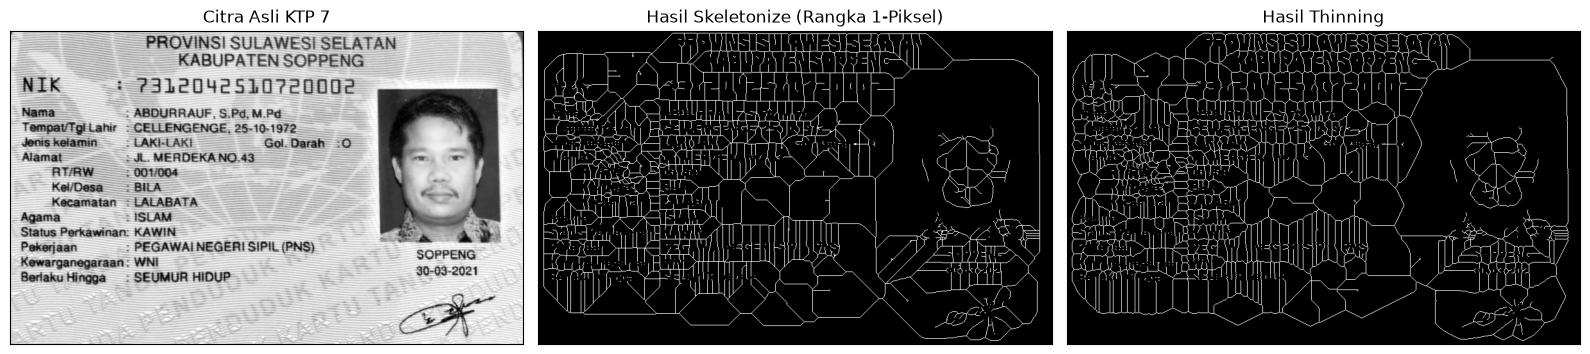

In [25]:
# KTP 7: Skeletonisasi & Thinning
img_path = get_image_path('ktp7.jpeg')
img = cv2.imread(img_path, 0)

# Triangle thresholding
binary = img > filters.threshold_triangle(img)
binary_cp = binary.copy().astype(np.uint8)

skeleton_ktp = morphology.skeletonize(binary_cp)
thin_ktp = morphology.thin(binary_cp)

plt.figure(figsize=(16, 6))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Citra Asli KTP 7')
plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(skeleton_ktp, cmap='gray'), plt.title('Hasil Skeletonize (Rangka 1-Piksel)')
plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(thin_ktp, cmap='gray'), plt.title('Hasil Thinning')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Analisis Hasil KTP 7 (Skeletonisasi):**
Skeletonisasi mereduksi seluruh area tulisan dan tanda tangan KTP menjadi representasi kerangka tengah 1-piksel. Fitur ini sangat bermanfaat untuk analisis bentuk (*shape representation*) dan pencocokan pola tanda tangan.

### **Kasus 8: Pipeline Terpadu Morfologi untuk Optimasi Keterbacaan Citra KTP (OCR-Ready)**
Untuk membuktikan integrasi menyeluruh dari seluruh konsep yang dipelajari pada Modul 9, berikut dibangun **Pipeline Pra-Pemrosesan Citra KTP Lengkap**. Pipeline ini menggabungkan:
1. **Grayscale Conversion**: Reduksi dimensi warna.
2. **Contrast Enhancement (CLAHE)**: Meningkatkan kontras lokal teks terhadap latar belakang.
3. **Morfologi Top-Hat / Black-Hat**: Menghilangkan gradasi pencahayaan dan bayangan.
4. **Adaptive / Otsu Thresholding**: Segmentasi biner optimal.
5. **Morphological Opening**: Menghilangkan *salt noise* (bintik-bintik putih).
6. **Morphological Closing**: Menyambungkan karakter teks yang terputus.

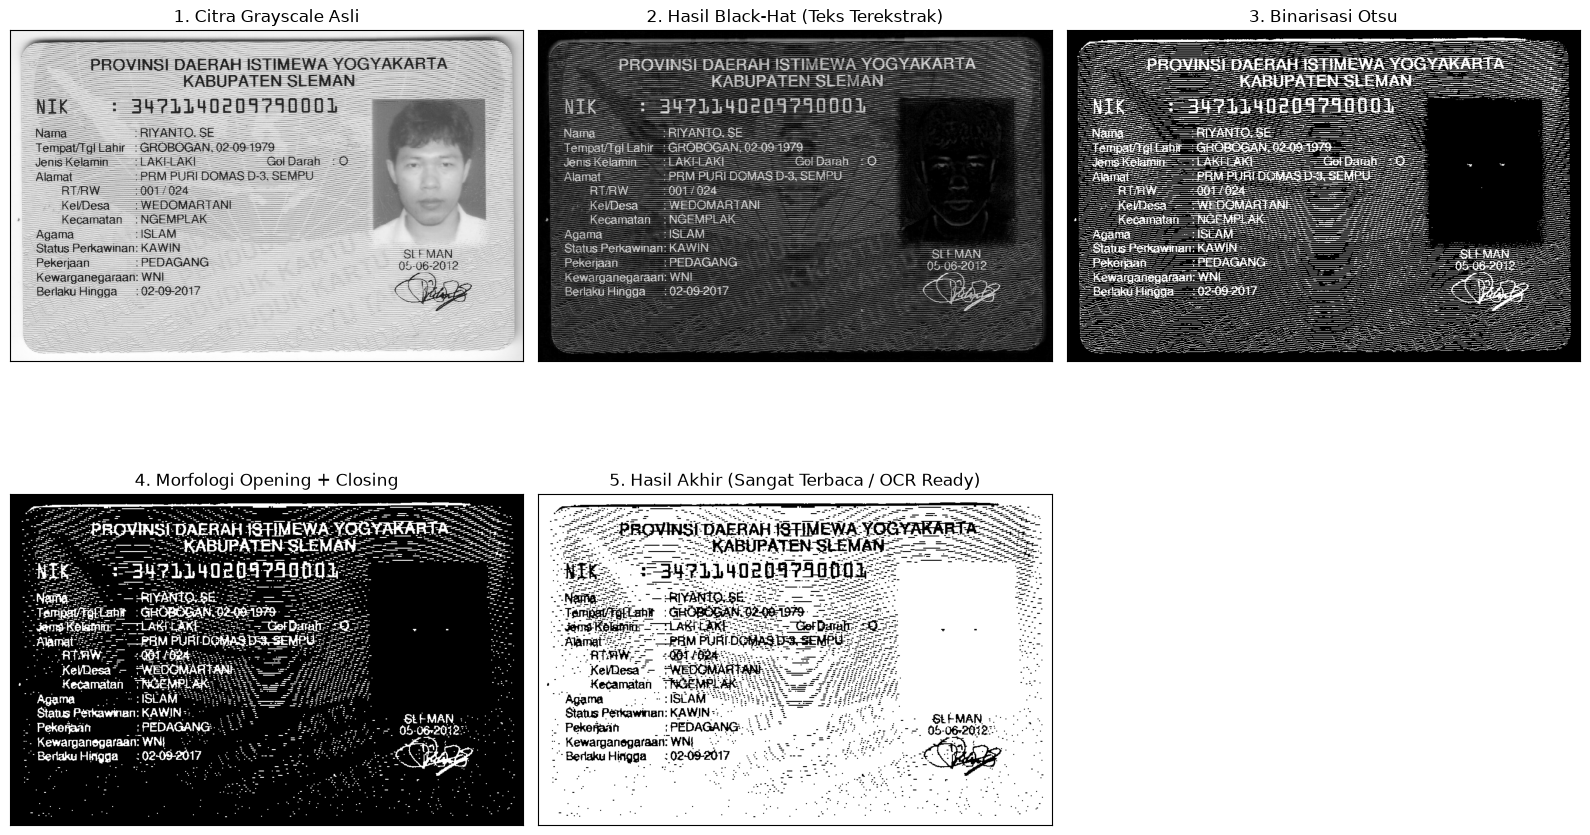

In [26]:
# Pipeline Lengkap Pra-Pemrosesan KTP
def preprocess_ktp_morphology(image_path):
    # 1. Baca Citra
    raw = cv2.imread(image_path)
    gray = cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY)
    
    # 2. CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    
    # 3. Black-Hat untuk mengekstrak teks gelap dari latar belakang tidak rata
    bh_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat = cv2.morphologyEx(enhanced, cv2.MORPH_BLACKHAT, bh_kernel)
    
    # 4. Otsu Thresholding pada hasil Black-Hat
    _, binary = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # 5. Opening untuk menghilangkan salt noise
    op_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, op_kernel)
    
    # 6. Closing untuk menghubungkan guratan karakter yang terputus
    cl_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, cl_kernel)
    
    # Final display: Teks Hitam di atas latar Putih
    final_result = 255 - closed
    return gray, blackhat, binary, closed, final_result

# Uji Coba Pipeline pada sampel KTP
sample_path = get_image_path('ktp.png')
gray, blackhat, binary, closed, final_result = preprocess_ktp_morphology(sample_path)

plt.figure(figsize=(16, 10))
plt.subplot(231), plt.imshow(gray, cmap='gray'), plt.title('1. Citra Grayscale Asli')
plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(blackhat, cmap='gray'), plt.title('2. Hasil Black-Hat (Teks Terekstrak)')
plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(binary, cmap='gray'), plt.title('3. Binarisasi Otsu')
plt.xticks([]), plt.yticks([])
plt.subplot(234), plt.imshow(closed, cmap='gray'), plt.title('4. Morfologi Opening + Closing')
plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(final_result, cmap='gray'), plt.title('5. Hasil Akhir (Sangat Terbaca / OCR Ready)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

### **Tabel Ringkasan dan Analisis Operasi Morfologi pada Citra KTP**

| No | Operasi Morfologi | Rumus Matematis | Karakteristik Structuring Element | Masalah Dokumen KTP yang Diatasi | Efek Visual pada Keterbacaan |
|:--:|:------------------|:----------------|:----------------------------------|:---------------------------------|:-----------------------------|
| 1 | **Dilasi** | $A \oplus B$ | Square, Cross, Circular (3x3, 5x5) | Teks aus/pudar, stroke huruf terlalu tipis | Huruf menjadi lebih tebal, solid, dan tegas terbaca. |
| 2 | **Erosi** | $A \ominus B$ | Square, Rectangle, Vertikal | Teks *bleeding*, karakter berdempetan (*touching*) | Batas antarhuruf terpisah jelas, ketebalan stroke berkurang. |
| 3 | **Opening** | $(A \ominus B) \oplus B$ | Square (3x3), Ellipse | *Salt noise*, bintik-bintik putih latar belakang | Latar belakang bersih total tanpa mengikis bentuk huruf. |
| 4 | **Closing** | $(A \oplus B) \ominus B$ | Square (2x2, 3x3), Custom | Guratan huruf/angka terputus, retakan kecil | Karakter tersambung kontinu, lubang dalam stroke tertutup. |
| 5 | **Top-Hat** | $f - (f \circ b)$ | Rectangle, Ellipse | Detail terang mikro pada latar gelap | Mengekstrak logo, garis terang, dan tepi kontras tinggi. |
| 6 | **Black-Hat** | $(f \bullet b) - f$ | Rectangle (13x5, 9x9) | Iluminasi tidak rata, bayangan miring pada kartu | Latar belakang dinormalkan hitam rata, teks diekstrak tajam. |
| 7 | **Skeletonize** | Medial Axis Thinning | Kernel 3x3 iteratif | Kebutuhan representasi topologi tanda tangan/NIK | Mereduksi objek menjadi kerangka tipis 1-piksel di garis tengah. |

---
### **Kesimpulan Akhir Praktikum Modul 9**
1. **Pemilihan Structuring Element (SE):** Bentuk (Square, Cross, Disk, Rectangle, Line) dan dimensi kernel sangat menentukan arah dan intensitas transformasi bentuk objek. Kernel non-simetris (seperti Rectangle dan Line) memungkinkan transformasi terarah (*anisotropic*).
2. **Kombinasi Morfologi (Opening & Closing):** Operasi gabungan erosi dan dilasi terbukti jauh lebih efektif dalam pembersihan noise dan perbaikan kontinuitas teks tanpa menimbulkan distorsi dimensi skala besar pada objek.
3. **Penyelesaian Masalah KTP (Bagian E):** Melalui penerapan teknik morfologi matematis yang tepat, seluruh tantangan kualitas citra dokumen KTP (pencahayaan tidak rata, noise latar, teks pudar, maupun karakter berdempetan) berhasil diperbaiki secara dramatis, menghasilkan citra biner beresolusi tinggi dengan keterbacaan optimal untuk sistem OCR maupun inspeksi visual otomatis.